# Классификация звуков: ESC-50 → 10 классов

Датасет [ESC-50](https://github.com/karolpiczak/ESC-50): 2000 клипов по 5 с, 50 классов, 5 фолдов.
Берём официальное подмножество **ESC-10** (колонка `esc10`): 10 классов × 40 клипов = 400 клипов.

Признаки — **log-mel спектрограммы**. Модели:
1. **Линейная** — логистическая регрессия на статистиках спектрограммы (mean/std по времени для каждой mel-полосы);
2. **CNN** — 2D-свёрточная сеть на спектрограмме как на картинке;
3. **Transformer (с нуля)** — кадры спектрограммы → токены → TransformerEncoder;
4. **AST (предобученный)** — Audio Spectrogram Transformer (AudioSet), замороженный энкодер + линейная голова.

Разбиение: фолды 1–4 — train (320), фолд 5 — test (80), как в официальном протоколе.

In [1]:
# !pip install librosa transformers
import os, time, zipfile, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa, librosa.display
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
SR, N_MELS, HOP = 16000, 64, 320   # 16 кГц (нужно для AST), 5 с → 251 кадр
ROOT = 'ESC-50-master'
print(device)

cuda


## Данные
Архив ~600 МБ скачивается один раз.

In [2]:
if not os.path.exists(ROOT):
    urllib.request.urlretrieve('https://github.com/karolpiczak/ESC-50/archive/master.zip', 'esc50.zip')
    zipfile.ZipFile('esc50.zip').extractall('.')

meta = pd.read_csv(f'{ROOT}/meta/esc50.csv')
meta = meta[meta.esc10].reset_index(drop=True)          # оставляем 10 классов
classes = sorted(meta.category.unique())
meta['y'] = meta.category.map({c: i for i, c in enumerate(classes)})
print(len(meta), classes)

400 ['chainsaw', 'clock_tick', 'crackling_fire', 'crying_baby', 'dog', 'helicopter', 'rain', 'rooster', 'sea_waves', 'sneezing']


In [3]:
waves = np.stack([librosa.util.fix_length(librosa.load(f'{ROOT}/audio/{f}', sr=SR)[0], size=5 * SR)
                  for f in tqdm(meta.filename)])

def logmel(w):
    S = librosa.feature.melspectrogram(y=w, sr=SR, n_fft=1024, hop_length=HOP, n_mels=N_MELS)
    return librosa.power_to_db(S, ref=np.max)

specs = np.stack([logmel(w) for w in waves]).astype(np.float32)   # (400, 64, 251)

tr, te = (meta.fold != 5).values, (meta.fold == 5).values
y_tr, y_te = meta.y.values[tr], meta.y.values[te]
mu, sd = specs[tr].mean(), specs[tr].std()
X_tr, X_te = (specs[tr] - mu) / sd, (specs[te] - mu) / sd          # нормализация по train
print(specs.shape, X_tr.shape, X_te.shape)

  0%|          | 0/400 [00:00<?, ?it/s]

(400, 64, 251) (320, 64, 251) (80, 64, 251)


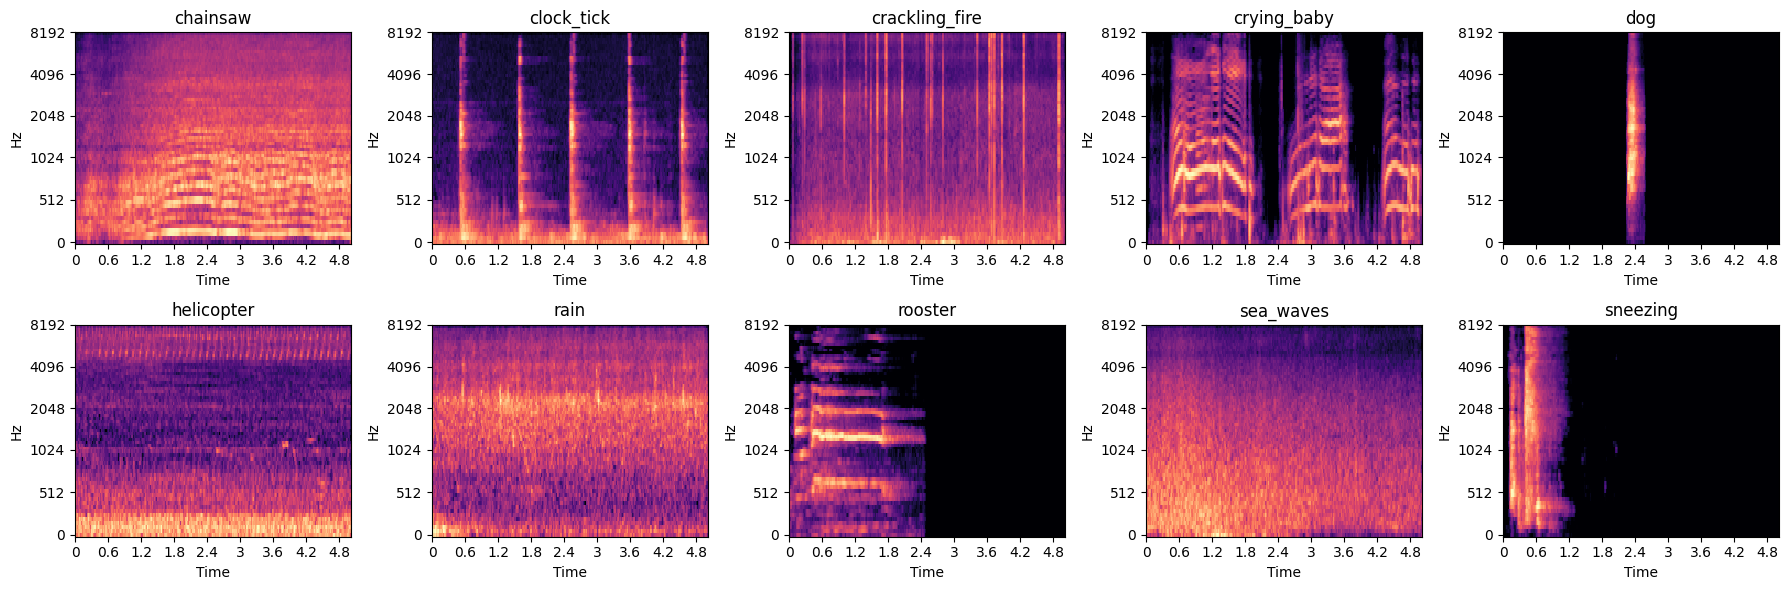

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, c in zip(axes.flat, classes):
    i = meta.index[meta.category == c][0]
    librosa.display.specshow(specs[i], sr=SR, hop_length=HOP, x_axis='time', y_axis='mel', ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

## Метрики

In [5]:
results, preds = {}, {}
def report(name, y_pred, t):
    preds[name] = y_pred
    results[name] = dict(accuracy=accuracy_score(y_te, y_pred),
                         f1_macro=f1_score(y_te, y_pred, average='macro'),
                         precision=precision_score(y_te, y_pred, average='macro', zero_division=0),
                         recall=recall_score(y_te, y_pred, average='macro'),
                         time_s=t)
    print(name, {k: round(v, 3) for k, v in results[name].items()})

## 1. Линейная модель
Спектрограмма сворачивается в вектор: среднее и std каждой mel-полосы по времени (128 признаков).

In [6]:
stats = lambda S: np.concatenate([S.mean(2), S.std(2)], 1)

t0 = time.time()
lin = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
lin.fit(stats(X_tr), y_tr)
report('LogReg', lin.predict(stats(X_te)), time.time() - t0)

LogReg {'accuracy': 0.787, 'f1_macro': 0.787, 'precision': 0.797, 'recall': 0.787, 'time_s': 0.199}


## Общий цикл обучения для нейросетей
Данных мало (320 клипов), поэтому аугментации на спектрограмме: циклический сдвиг по времени + SpecAugment (маски по частоте и времени),
label smoothing и OneCycle-шедулер.

In [7]:
def spec_augment(x):                       # x: (B, M, T)
    x = torch.roll(x, np.random.randint(x.shape[2]), dims=2)
    B, M, T = x.shape
    for b in range(B):
        f, t = np.random.randint(1, 12), np.random.randint(1, 40)
        f0, t0 = np.random.randint(0, M - f), np.random.randint(0, T - t)
        x[b, f0:f0 + f] = 0; x[b, :, t0:t0 + t] = 0
    return x

def train_torch(model, epochs=40, lr=1e-3, bs=32):
    model.to(device)
    Xtr, ytr = torch.tensor(X_tr), torch.tensor(y_tr)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * int(np.ceil(len(Xtr) / bs)))
    for ep in range(epochs):
        model.train(); perm, total = torch.randperm(len(Xtr)), 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = spec_augment(Xtr[idx].clone()).to(device), ytr[idx].to(device)
            loss = F.cross_entropy(model(xb), yb, label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            total += loss.item() * len(idx)
        if (ep + 1) % 10 == 0:
            print(f'epoch {ep + 1}: loss {total / len(Xtr):.3f}')
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X_te).to(device)).argmax(1).cpu().numpy()

n_params = lambda m: sum(p.numel() for p in m.parameters())

## 2. CNN
4 свёрточных блока (Conv-BN-ReLU-MaxPool) → global average pooling → линейный слой.

In [8]:
class CNN(nn.Module):
    def __init__(self, n_cls=10):
        super().__init__()
        block = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.net = nn.Sequential(block(1, 32), block(32, 64), block(64, 128), block(128, 128),
                                 nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_cls))
    def forward(self, x):
        return self.net(x.unsqueeze(1))

torch.manual_seed(SEED)
cnn = CNN(); print('params:', n_params(cnn))
t0 = time.time()
report('CNN', train_torch(cnn, epochs=40), time.time() - t0)

params: 242250
epoch 10: loss 1.289
epoch 20: loss 1.011
epoch 30: loss 0.871
epoch 40: loss 0.811
CNN {'accuracy': 0.812, 'f1_macro': 0.814, 'precision': 0.84, 'recall': 0.812, 'time_s': 22.416}


## 3. Transformer с нуля
Каждые 4 кадра спектрограммы (64 mel × 4) проецируются Conv1d в токен размерности 128 → 62 токена + позиционные эмбеддинги →
4 слоя TransformerEncoder → mean pooling → классификатор.

In [9]:
class SpecTransformer(nn.Module):
    def __init__(self, n_frames=X_tr.shape[2], d=128, depth=4, heads=4, patch=4, n_cls=10):
        super().__init__()
        self.embed = nn.Conv1d(N_MELS, d, patch, stride=patch)
        self.pos = nn.Parameter(torch.randn(1, n_frames // patch, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, n_cls))
    def forward(self, x):                           # (B, M, T)
        x = self.embed(x).transpose(1, 2) + self.pos  # (B, T/4, d)
        return self.head(self.enc(x).mean(1))

torch.manual_seed(SEED)
tf = SpecTransformer(); print('params:', n_params(tf))
t0 = time.time()
report('Transformer (scratch)', train_torch(tf, epochs=60, lr=5e-4), time.time() - t0)

params: 572298
epoch 10: loss 1.281
epoch 20: loss 1.005
epoch 30: loss 0.796
epoch 40: loss 0.716
epoch 50: loss 0.672
epoch 60: loss 0.664
Transformer (scratch) {'accuracy': 0.787, 'f1_macro': 0.786, 'precision': 0.802, 'recall': 0.787, 'time_s': 13.633}


## 4. AST — предобученный Audio Spectrogram Transformer
`MIT/ast-finetuned-audioset-10-10-0.4593`: внутри строит 128-mel fbank-спектрограмму, режет её на патчи 16×16 (как ViT).
Энкодер заморожен — один раз считаем эмбеддинги (`pooler_output`, 768) и кэшируем, сверху логистическая регрессия.
На CPU извлечение займёт несколько минут.

In [10]:
from transformers import ASTFeatureExtractor, ASTModel

AST_NAME, CACHE = 'MIT/ast-finetuned-audioset-10-10-0.4593', 'ast_emb_esc10.npy'
t0 = time.time()
if os.path.exists(CACHE):
    emb = np.load(CACHE)
else:
    fe = ASTFeatureExtractor.from_pretrained(AST_NAME)
    ast = ASTModel.from_pretrained(AST_NAME).to(device).eval()
    out = []
    with torch.no_grad():
        for i in tqdm(range(0, len(waves), 16)):
            inp = fe(list(waves[i:i + 16]), sampling_rate=SR, return_tensors='pt').to(device)
            out.append(ast(**inp).pooler_output.cpu().numpy())
    emb = np.concatenate(out); np.save(CACHE, emb)

ast_clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
ast_clf.fit(emb[tr], y_tr)
report('AST (pretrained)', ast_clf.predict(emb[te]), time.time() - t0)

preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

c:\Users\Lenovo\miniconda3\envs\jupyter_env\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lenovo\.cache\huggingface\hub\models--MIT--ast-finetuned-audioset-10-10-0.4593. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

c:\Users\Lenovo\miniconda3\envs\jupyter_env\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lenovo\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/25 [00:00<?, ?it/s]

AST (pretrained) {'accuracy': 0.988, 'f1_macro': 0.987, 'precision': 0.989, 'recall': 0.988, 'time_s': 135.878}


## Сравнение

,accuracy,f1_macro,precision,recall,time_s
AST (pretrained),0.988,0.987,0.989,0.988,135.878
CNN,0.812,0.814,0.840,0.812,22.416
LogReg,0.787,0.787,0.797,0.787,0.199
Transformer (scratch),0.787,0.786,0.802,0.787,13.633


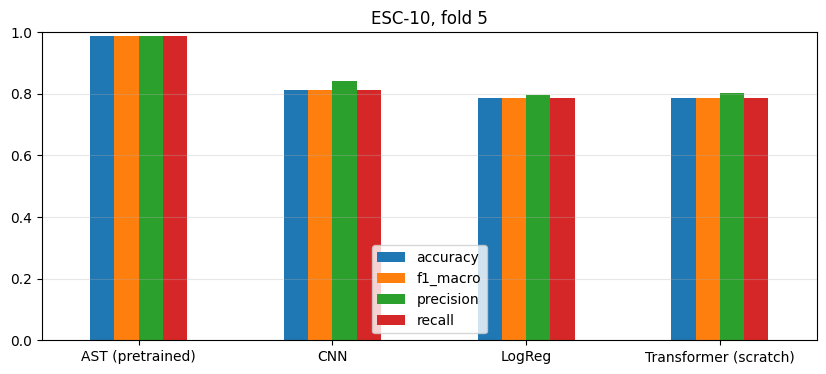

In [11]:
res = pd.DataFrame(results).T.sort_values('f1_macro', ascending=False)
display(res.style.format('{:.3f}').highlight_max(subset=['accuracy', 'f1_macro', 'precision', 'recall']))

res[['accuracy', 'f1_macro', 'precision', 'recall']].plot.bar(figsize=(10, 4), rot=0, ylim=(0, 1))
plt.title('ESC-10, fold 5'); plt.grid(axis='y', alpha=.3); plt.show()

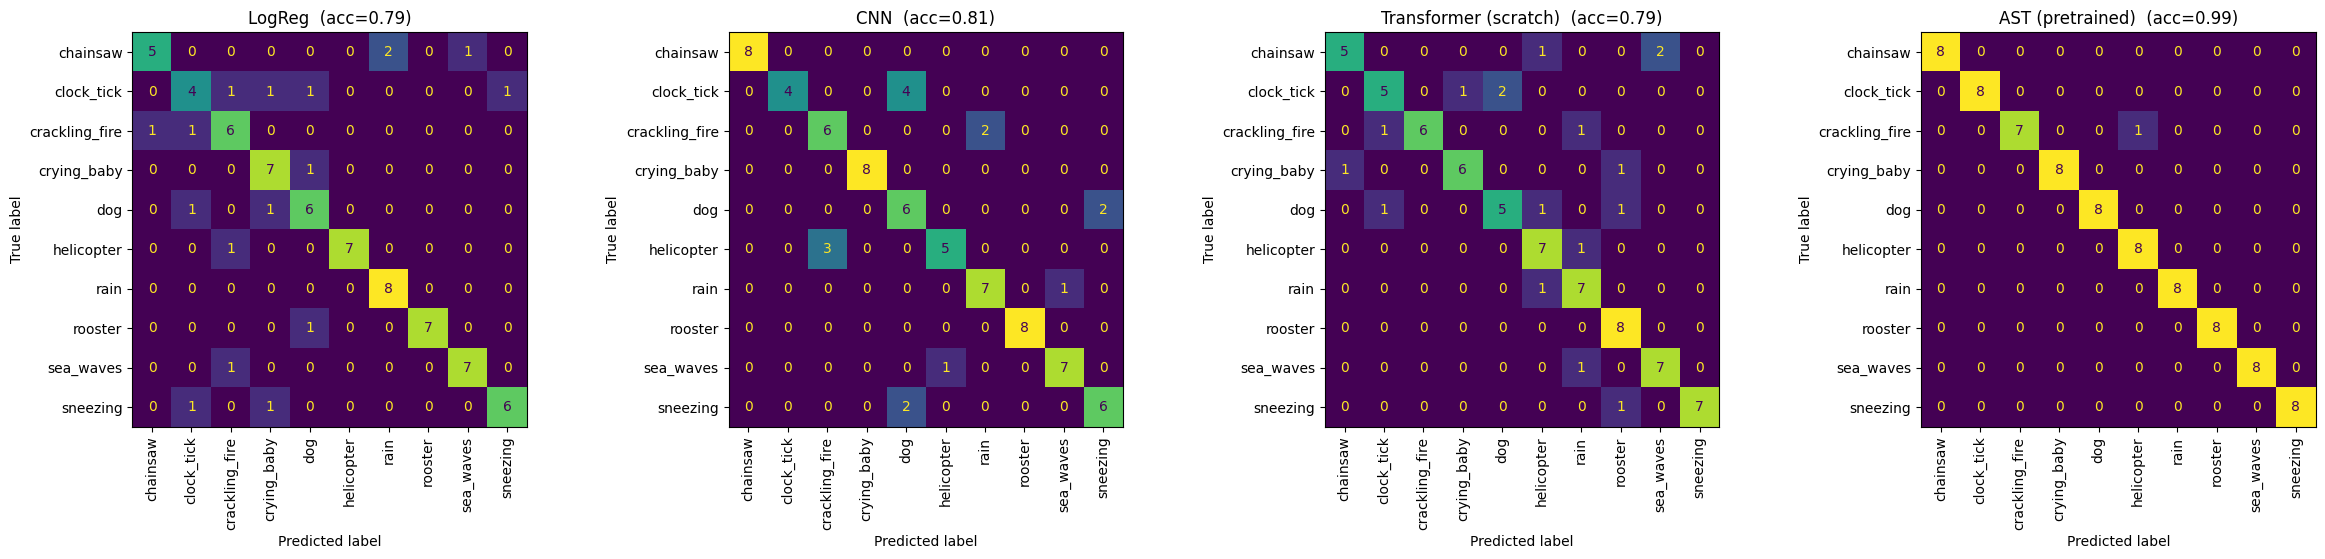

In [12]:
fig, axes = plt.subplots(1, len(preds), figsize=(6 * len(preds), 5.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, p), display_labels=classes).plot(
        ax=ax, colorbar=False, xticks_rotation=90)
    ax.set_title(f"{name}  (acc={results[name]['accuracy']:.2f})")
plt.tight_layout(); plt.show()